In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2B0
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [2]:
!unzip -q /content/data.zip -d /content/

replace /content/data/seg_pred/seg_pred/10004.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


In [3]:
IMG_SIZE      = 150
BATCH_SIZE    = 8
EPOCHS_FROZEN = 10
EPOCHS_FINETUNE = 15
LR_HEAD       = 1e-3
LR_FINETUNE   = 1e-5
TRAIN_DIR = "/content/data/seg_train/seg_train"
TEST_DIR  = "/content/data/seg_test/seg_test"
CLASS_NAMES   = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
NUM_CLASSES   = len(CLASS_NAMES)

tf.random.set_seed(42)
np.random.seed(42)

In [4]:
print("Loading datasets …")

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASS_NAMES,
    shuffle=True,
    seed=42,
)

train_size  = int(0.85 * len(train_ds))
val_ds      = train_ds.skip(train_size)
train_ds    = train_ds.take(train_size)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASS_NAMES,
    shuffle=False,
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Loading datasets …
Found 14034 files belonging to 6 classes.
Found 3000 files belonging to 6 classes.


In [5]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="data_augmentation")

def build_model(trainable_base=False):
    base_model = EfficientNetV2B0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_preprocessing=True,
    )
    base_model.trainable = trainable_base

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = base_model(x, training=trainable_base)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs)

In [6]:
print("\n Training classification head")
model = build_model(trainable_base=False)
model.summary()

model.compile(
    optimizer=keras.optimizers.Adam(LR_HEAD),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_phase1 = [
    keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_accuracy"),
    keras.callbacks.ModelCheckpoint("best_head.keras", save_best_only=True, monitor="val_accuracy"),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FROZEN,
    callbacks=callbacks_phase1,
)


 Training classification head


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 5, 5, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,253,910 (23.86 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 5,921,872 (22.59 MB)

Epoch 1/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 70s 35ms/step - accuracy: 0.7721 - loss: 0.7258 - val_accuracy: 0.8989 - val_loss: 0.2888
Epoch 2/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.8107 - loss: 0.5176 - val_accuracy: 0.8803 - val_loss: 0.3400
Epoch 3/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 31s 21ms/step - accuracy: 0.8284 - loss: 0.4660 - val_accuracy: 0.8998 - val_loss: 0.2968
Epoch 4/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.8357 - loss: 0.4526 - val_accuracy: 0.8998 - val_loss: 0.3014
Epoch 5/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.8371 - loss: 0.4441 - val_accuracy: 0.9122 - val_loss: 0.2731
Epoch 6/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.8428 - loss: 0.4322 - val_accuracy: 0.9003 - val_loss: 0.2777
Epoch 7/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 32s 22ms/step - accuracy: 0.8442 - loss: 0.4215 - val_accuracy: 0.9141 - val_loss: 0.2622
Epoch 8/10
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.8442 -

In [7]:
print("\n Fine-tuning top layers of the model")

model.layers[2].trainable = True

base = model.layers[2]
for layer in base.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(LR_FINETUNE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_phase2 = [
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_accuracy"),
    keras.callbacks.ModelCheckpoint("best_finetuned.keras", save_best_only=True, monitor="val_accuracy"),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, monitor="val_accuracy"),
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINETUNE,
    callbacks=callbacks_phase2,
)


 Fine-tuning top layers of the model
Epoch 1/15
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 143s 75ms/step - accuracy: 0.7270 - loss: 0.7382 - val_accuracy: 0.8765 - val_loss: 0.3555 - learning_rate: 1.0000e-05
Epoch 2/15
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 108s 73ms/step - accuracy: 0.7862 - loss: 0.5909 - val_accuracy: 0.8922 - val_loss: 0.3136 - learning_rate: 1.0000e-05
Epoch 3/15
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 108s 72ms/step - accuracy: 0.8042 - loss: 0.5231 - val_accuracy: 0.9008 - val_loss: 0.2886 - learning_rate: 1.0000e-05
Epoch 4/15
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 108s 73ms/step - accuracy: 0.8234 - loss: 0.5020 - val_accuracy: 0.9074 - val_loss: 0.2642 - learning_rate: 1.0000e-05
Epoch 5/15
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 108s 72ms/step - accuracy: 0.8301 - loss: 0.4728 - val_accuracy: 0.9065 - val_loss: 0.2698 - learning_rate: 1.0000e-05
Epoch 6/15
1491/1491 ━━━━━━━━━━━━━━━━━━━━ 109s 73ms/step - accuracy: 0.8416 - loss: 0.4366 - val_accuracy: 0.9093 - val_loss: 0.2559 - learning_rate: 1.0000e


 Test set evaluation
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9187 - loss: 0.2506
Test accuracy : 0.9187
Test loss     : 0.2506

Classification Report:
              precision    recall  f1-score   support

   buildings       0.93      0.94      0.93       437
      forest       0.99      1.00      0.99       474
     glacier       0.88      0.84      0.86       553
    mountain       0.87      0.85      0.86       525
         sea       0.91      0.98      0.94       510
      street       0.95      0.93      0.94       501

    accuracy                           0.92      3000
   macro avg       0.92      0.92      0.92      3000
weighted avg       0.92      0.92      0.92      3000



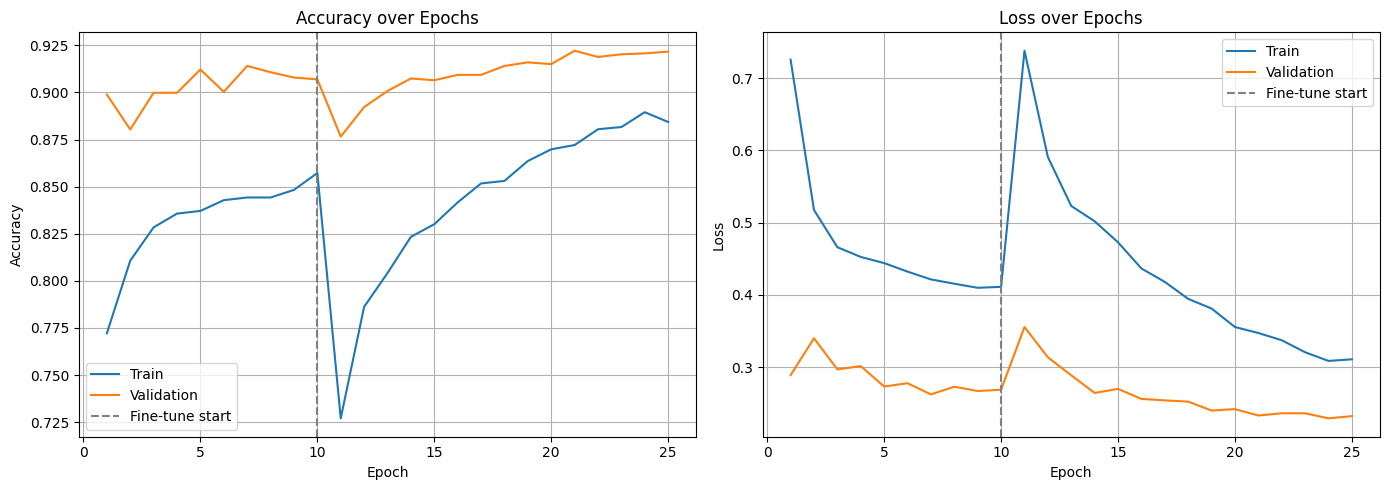

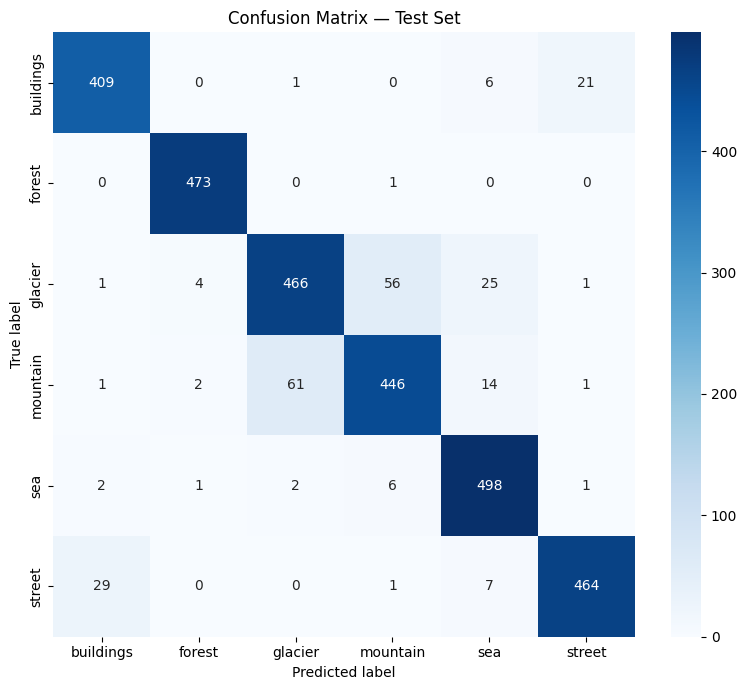


 best_finetuned.keras, training_curves.png, confusion_matrix.png


In [8]:
print("\n Test set evaluation")
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy : {test_acc:.4f}")
print(f"Test loss     : {test_loss:.4f}")

y_pred, y_true = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

def combine_histories(h1, h2, key):
    return h1.history[key] + h2.history[key]

epochs_total = range(1, len(combine_histories(history1, history2, "accuracy")) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_total, combine_histories(history1, history2, "accuracy"),     label="Train")
axes[0].plot(epochs_total, combine_histories(history1, history2, "val_accuracy"), label="Validation")
axes[0].axvline(len(history1.history["accuracy"]), color="gray", linestyle="--", label="Fine-tune start")
axes[0].set_title("Accuracy over Epochs")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(True)

axes[1].plot(epochs_total, combine_histories(history1, history2, "loss"),     label="Train")
axes[1].plot(epochs_total, combine_histories(history1, history2, "val_loss"), label="Validation")
axes[1].axvline(len(history1.history["loss"]), color="gray", linestyle="--", label="Fine-tune start")
axes[1].set_title("Loss over Epochs")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — Test Set")
plt.ylabel("True label"); plt.xlabel("Predicted label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print("\n best_finetuned.keras, training_curves.png, confusion_matrix.png")